# AI-6 — End-to-End LoRA Fine-Tuning (Colab-compatible)

**Goal:** fine-tune a small open-source instruction model with PEFT LoRA, save the adapter, compare an untouched base model against the fine-tuned model on held-out prompts, and export evidence for GitHub.

**Important compatibility choice:** this notebook uses ordinary FP16 LoRA, not 4-bit LoRA. This avoids the bitsandbytes CUDA binary / Triton compatibility error seen in some current Colab Python 3.13 runtimes. The selected 0.5B model is small enough for LoRA training on a T4 GPU.

Run top-to-bottom in Google Colab. Select **Runtime → Change runtime type → T4 GPU** (or another supported NVIDIA GPU).

## 0. Install compatible training packages

This workflow intentionally does **not** install or import `bitsandbytes`. The current runtime reported that its CUDA 13 binary was missing and then failed at `triton.ops`. Standard FP16 LoRA does not need bitsandbytes.

Run this cell, then if Colab asks for a restart, restart the runtime and continue from Cell 4 onward (rerun setup and all cells in order).

In [1]:
%pip -q install "transformers==4.46.3" "peft==0.13.2" "accelerate==1.1.1" "datasets==3.1.0" "matplotlib>=3.8,<4"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Setup, reproducibility, and persistent output folder

In [2]:
import os, json, random, shutil, gc, sys, subprocess
from pathlib import Path
from datetime import datetime, timezone

SEED = 42
random.seed(SEED)
try:
    import numpy as np
    np.random.seed(SEED)
except Exception:
    pass

# Persist artifacts to Google Drive when running in Colab.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run")
except Exception:
    PROJECT_DIR = Path("/content/ai6_finetuning_project")

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "artifacts"
REPORT_DIR = PROJECT_DIR / "reports"
for folder in (DATA_DIR, OUTPUT_DIR, REPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Project directory:", PROJECT_DIR)
print("Artifacts persist to Drive when Drive is mounted.")

Mounted at /content/drive
Python: 3.13.16
Project directory: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run
Artifacts persist to Drive when Drive is mounted.


## 2. Define a small, focused authored dataset

These examples are intentionally authored for this learning project instead of relying on noisy scraped datasets. They cover concise AI/ML engineering explanations. Review and improve them before using the adapter in a real application.

In [3]:
examples = [
("What is gradient descent in machine learning?", "Gradient descent is an optimization method that updates model parameters in the direction that reduces a loss function. A learning rate controls the update size, and the process repeats until a stopping condition is met."),
("Explain overfitting and one way to reduce it.", "Overfitting occurs when a model learns training-specific patterns that do not generalize. Useful controls include regularization, early stopping, simpler models, data augmentation, and evaluation on a separate validation set."),
("What is the difference between classification and regression?", "Classification predicts a discrete class or category, while regression predicts a continuous numeric value. The task determines suitable loss functions, metrics, and output layers."),
("Why split data into training, validation, and test sets?", "Training data fits model parameters, validation data guides model or hyperparameter choices, and test data provides a final estimate after choices are complete. Reusing test data for tuning makes the estimate optimistic."),
("What is data leakage in machine learning?", "Data leakage occurs when training uses information that would not legitimately be available at prediction time, or information derived from the evaluation target. It can produce misleadingly strong metrics."),
("What is precision in classification?", "Precision is true positives divided by all predicted positives. It answers: among items predicted positive, what fraction were actually positive? It is useful when false positives are costly."),
("What is recall in classification?", "Recall is true positives divided by all actual positives. It measures how many positive cases the model finds and matters when missing a positive case is costly."),
("What is feature engineering?", "Feature engineering transforms raw inputs into useful model features using domain knowledge and training-only statistics where appropriate. Any learned transformation should be fitted on training data and then applied to validation and test data."),
("Why use a validation set?", "A validation set helps compare model versions and tune hyperparameters without repeatedly using the final test set. It should represent the intended deployment distribution as closely as practical."),
("What does a confusion matrix show?", "A confusion matrix counts actual versus predicted classes. It exposes false positives and false negatives and helps explain precision, recall, and class-specific performance."),
("What is a large language model?", "A large language model is a neural network trained on text or other token sequences to model language patterns. Instruction-tuned versions are further trained to follow requests, but can still produce incorrect answers."),
("What is tokenization in an LLM?", "Tokenization converts text into model-specific token IDs. Tokens may represent words, subwords, characters, or byte sequences, and token counts determine context length and part of inference cost."),
("What is the attention mechanism in a Transformer?", "Attention lets each token representation combine information from other tokens according to learned relevance weights. Self-attention is a central Transformer component, alongside feed-forward layers and residual connections."),
("What is LoRA fine-tuning?", "LoRA freezes most pretrained weights and trains small low-rank matrices inserted into selected model layers. This reduces trainable parameters and storage while adapting the model to a task."),
("What is LoRA?", "LoRA fine-tunes small low-rank adapter weights while keeping the original base-model weights frozen. In this notebook the base model is loaded in FP16, not 4-bit quantized; this uses more memory than QLoRA but avoids the current bitsandbytes CUDA/Triton import issue."),
("What is the difference between fine-tuning and RAG?", "Fine-tuning updates model parameters to change behavior or specialize patterns. Retrieval-augmented generation fetches external evidence at inference time and places it in the prompt. They solve different problems and can be combined."),
("What is quantization for neural networks?", "Quantization represents weights or activations with lower-precision numeric formats. It can reduce memory and sometimes improve throughput, but quality and speed depend on the model, hardware, and quantization method."),
("What is a context window?", "A context window is the maximum token sequence a model can process for a request, including relevant prompt and generated tokens according to the model's implementation. Long inputs may need careful truncation or retrieval."),
("What is retrieval-augmented generation?", "Retrieval-augmented generation retrieves relevant passages from an external corpus and supplies them to a language model as context. Quality depends on document preparation, retrieval relevance, context construction, and grounded answer generation."),
("Why chunk documents in a RAG system?", "Chunking divides long documents into retrievable units. Good chunk sizes preserve enough context while keeping retrieval focused; overlap can preserve boundaries but too much overlap adds redundancy."),
("What is an embedding?", "An embedding is a numeric vector representing an item such as text. Embedding models aim to place semantically related items near each other in vector space, enabling similarity search and retrieval."),
("What is cosine similarity?", "Cosine similarity compares the angle between two vectors. It is often used to rank semantic embeddings, but its usefulness depends on the embedding model and whether vectors are normalized."),
("What is a vector database used for?", "A vector database stores vectors and supports nearest-neighbor search, often with metadata filters. In RAG, it can retrieve document chunks related to a user's query."),
("What is MLOps?", "MLOps applies engineering practices to the machine-learning lifecycle, including reproducible training, deployment, monitoring, versioning, and controlled updates. Its goal is reliable operation rather than only a good offline score."),
("What is data drift?", "Data drift is a change in the distribution of input data over time. It can be monitored using summary statistics or drift metrics, but drift alone does not prove that model performance has degraded."),
("What is concept drift?", "Concept drift is a change in the relationship between inputs and the target outcome. Monitoring labels and outcome metrics can help detect it, though labels may arrive late."),
("Why monitor a deployed model?", "Monitoring can track latency, errors, input distributions, resource use, and—when labels arrive—prediction quality. Alerts should have clear thresholds and an actionable response plan."),
("What is a canary deployment?", "A canary deployment routes a small portion of traffic to a new version first. Teams compare health and quality signals, then expand traffic or roll back if the new version behaves poorly."),
("Why track model and dataset versions?", "Versioning makes experiments reproducible and helps connect predictions to the model, data, code, and configuration that produced them. It also supports audits and rollbacks."),
("What is a Python virtual environment?", "A Python virtual environment isolates a project's installed packages from other projects. It helps make dependencies reproducible and reduces version conflicts."),
("How should Python exceptions be handled?", "Catch exceptions you can meaningfully handle, log enough context to diagnose failures, and avoid silently swallowing errors. Prefer narrow exception types over a broad catch unless a boundary must record and re-raise unexpected failures."),
("What is a unit test?", "A unit test checks a small unit of behavior in isolation. Good tests cover normal cases, edge cases, and expected failures, and should be deterministic and easy to diagnose."),
("Why use type hints in Python?", "Type hints document expected values and help editors and static analyzers find some mistakes. Python does not enforce most annotations at runtime by default."),
("What is reproducibility in ML experiments?", "Reproducibility means recording data versions, random seeds, code, package versions, hardware, and configuration so results can be repeated or explained. Some GPU operations may remain nondeterministic."),
("What is a learning rate?", "The learning rate controls the size of parameter updates during optimization. Too high a value can destabilize training, while too low a value can make learning slow or ineffective."),
("What is early stopping?", "Early stopping ends training when a monitored validation metric stops improving according to a chosen patience rule. It can reduce overfitting, but the validation set must not be treated as the final test set."),
("What is regularization?", "Regularization discourages overly complex solutions, for example through weight decay or dropout. It can improve generalization, but excessive regularization may cause underfitting."),
("What is a baseline model?", "A baseline is a simple reference model or existing system against which a new approach is compared. It makes improvements measurable and helps reveal when added complexity is not worthwhile."),
("Why evaluate a model on held-out data?", "Held-out data estimates performance on examples not used to fit parameters. It reduces the risk of reporting memorization as generalization, especially when the split avoids duplicates and leakage."),
("What is prompt engineering?", "Prompt engineering structures instructions, context, constraints, and examples to guide a language model. It can improve task clarity but does not guarantee factual correctness or eliminate model limitations."),
("What is an inference server?", "An inference server hosts a model behind an interface and manages request processing. Useful capabilities can include batching, concurrency, health checks, metrics, and model-version management."),
("What is the KV cache in Transformer inference?", "The key-value cache stores attention keys and values from earlier tokens so autoregressive generation does not recompute them each step. It speeds decoding but consumes memory that grows with sequence length and batch size."),
("What is model quantization's main trade-off?", "Quantization can lower memory use and improve deployment efficiency, but may reduce accuracy or behave differently across hardware. The right choice should be measured on representative prompts and workloads."),
("How can RAG hallucinations be reduced?", "Retrieve relevant, trustworthy passages; include source context; instruct the model to acknowledge missing evidence; and evaluate groundedness on held-out questions. These controls reduce risk but do not guarantee zero hallucinations."),
("What is semantic search?", "Semantic search retrieves items based on vector representations of meaning rather than exact keyword overlap alone. It can find paraphrases, but quality depends on embedding coverage and the retrieval corpus."),
("What is a reranker in retrieval?", "A reranker scores an initial set of retrieved candidates more carefully and reorders them. It can improve relevance at extra latency and compute cost, so evaluate it on task-specific queries."),
("What is the purpose of a model registry?", "A model registry stores model versions and associated metadata such as metrics, lineage, approvals, and deployment status. It supports controlled promotion and rollback."),
("What is an A/B test for ML systems?", "An A/B test compares versions on separate traffic groups using predefined metrics and safeguards. Randomization, adequate sample size, and monitoring for unintended effects are important for credible conclusions."),
("What is a training-serving skew?", "Training-serving skew occurs when feature processing or data distributions differ between training and production. Shared transformations, schema checks, and monitoring can help identify it."),
("What is data validation in an ML pipeline?", "Data validation checks schemas, ranges, missingness, categories, and other expectations before training or inference. Validation can catch broken inputs early but must reflect legitimate data variation."),
("What is the purpose of a learning-rate scheduler?", "A learning-rate scheduler changes the learning rate during training according to a predefined rule or monitored metric. Warmup and decay schedules can stabilize early updates and refine later optimization."),
("What is gradient accumulation?", "Gradient accumulation sums gradients across several microbatches before an optimizer update. It can simulate a larger effective batch size when memory is limited, although it does not remove all differences from a true large batch."),
("Why use gradient checkpointing?", "Gradient checkpointing saves memory by recomputing some intermediate activations during backpropagation. It trades extra computation for lower memory use."),
("What does a LoRA rank control?", "LoRA rank controls the size of the trainable low-rank update. Higher rank increases adapter capacity and parameter count, but does not guarantee better results and uses more memory."),
("What are LoRA target modules?", "Target modules are the model layers where adapter weights are inserted, commonly attention projections and sometimes feed-forward projections. Names vary by architecture, so inspect the model's module names before choosing targets."),
("What is catastrophic forgetting during fine-tuning?", "Catastrophic forgetting is a loss of previously learned capabilities after adapting a model to a narrower dataset. Small learning rates, carefully curated data, evaluation, and limited updates can help manage the risk."),
("Why should validation examples not be used for training?", "Validation examples guide model selection and should not contribute to gradient updates. Keeping them separate makes validation metrics more informative, although repeated tuning against them can still overfit the validation set."),
("What is the difference between an adapter and a full model checkpoint?", "An adapter stores parameter updates for a compatible base model, while a full checkpoint stores the complete model weights. An adapter is smaller but normally requires the matching base model to run."),
("What should a model card document?", "A model card should describe intended uses, limitations, training and evaluation data, evaluation results, risks, and relevant provenance. It helps users judge whether the model fits their use case."),
("Why should model outputs be evaluated manually as well as automatically?", "Automatic metrics can miss factual errors, relevance problems, and undesirable behavior. Human review complements metrics, especially for small datasets and qualitative tasks, though reviewers should use consistent criteria."),
("What is an evaluation benchmark?", "An evaluation benchmark is a defined set of tasks, examples, and metrics used to compare systems. It should represent the intended use and be protected against leakage or repeated tuning."),
("What is batch inference?", "Batch inference processes multiple examples together to improve hardware utilization. Larger batches can increase throughput but also affect latency and memory consumption."),
("What is latency versus throughput?", "Latency measures how long an individual request takes, while throughput measures how many requests or tokens are processed per unit time. Serving systems often balance both under memory and concurrency constraints."),
("Why use structured logging in ML services?", "Structured logs store fields such as request ID, model version, latency, and error category in a consistent format. Avoid logging secrets or sensitive user content, and apply appropriate retention controls."),
("What is a rollback strategy for model deployment?", "A rollback strategy defines how to return to a known-good model version when health or quality signals fail. Keep prior artifacts available and test the rollback process before relying on it."),
("What is model calibration?", "Calibration measures whether predicted probabilities correspond to observed frequencies. A well-calibrated model that assigns 0.8 probability to many cases should be correct about 80 percent of the time on those cases, approximately."),
("What is class imbalance?", "Class imbalance means some labels occur much more often than others. Accuracy can hide poor minority-class performance, so consider per-class precision and recall, suitable sampling, and task costs."),
("What is cross-validation?", "Cross-validation repeatedly trains and evaluates across different data folds to estimate variability. It must be designed to prevent related records or time-dependent leakage from crossing folds."),
("What is a data pipeline?", "A data pipeline automates repeatable steps that ingest, validate, transform, and deliver data. It should expose failures, preserve lineage, and make outputs reproducible."),
("What is a model endpoint health check?", "A health check reports whether a service can accept or process requests. Separate liveness from readiness where appropriate, and include dependency checks that reflect actual serving requirements."),
("What is a system prompt?", "A system prompt provides high-level behavior and constraints to a chat model. It can guide responses but is not a security boundary and cannot guarantee compliance with every instruction."),
("What is a hallucination in language models?", "A hallucination is an output that presents unsupported or false information as if it were true. Grounding, calibrated uncertainty, verification, and targeted evaluation can reduce risk but cannot eliminate it completely."),
("What is instruction tuning?", "Instruction tuning trains a model on examples pairing instructions with desired responses. It aims to improve instruction following, but results depend on data quality, diversity, and the training procedure."),
("What is the difference between supervised fine-tuning and preference tuning?", "Supervised fine-tuning learns from target responses provided in examples. Preference tuning uses comparisons or preference signals to shape outputs toward preferred behavior; each requires appropriate data and evaluation."),
("Why is a held-out test set important after fine-tuning?", "A held-out test set provides a final check after training and validation choices are complete. It should be used sparingly and should not become another tuning set."),
("How should an ML experiment record dependencies?", "Record package versions, Python and CUDA details, model revision, data hashes, random seeds, and key settings. Pinning versions improves reproducibility but does not guarantee identical results across hardware."),
("What is the role of a tokenizer in generation?", "A tokenizer maps text to token IDs before inference and maps generated IDs back to text. It must match the model's vocabulary and configuration to avoid incorrect input or decoding."),
("Why should generated outputs use a stopping token?", "A correct end-of-sequence token lets generation stop when the model finishes a response. Missing or mismatched stopping configuration can cause truncated answers or unwanted continuation."),
("What is the purpose of a validation loss?", "Validation loss measures the model's prediction loss on held-out examples and can help track generalization during training. It does not directly measure factual correctness or usefulness."),
("How can duplicate examples distort evaluation?", "Duplicates across train and evaluation sets can make results look better because the model may have seen the same content during training. Deduplicate and check for near-duplicates before splitting."),
("What is a safe way to handle secrets in notebooks?", "Do not hard-code API keys or credentials in notebook cells. Use secure secret management, restrict access, and avoid including secrets in logs or committed notebook outputs."),
("What does reproducible inference mean?", "Reproducible inference means recording model and tokenizer versions, prompt formatting, decoding settings, and runtime details. Deterministic decoding reduces sampling variation but does not ensure identical outputs across all software and hardware."),
("Why compare models with the same prompts?", "Using the same prompts controls one source of variation and makes output differences easier to inspect. A fair comparison also keeps decoding settings consistent and evaluates correctness rather than text difference alone."),
("What is a good practice for model release?", "A responsible release includes versioned artifacts, a clear model card, licensing checks, evaluation results, known limitations, and instructions for reproduction. Do not claim capabilities that the evidence does not support."),
]

# Deduplicate exact prompts and split deterministically.
seen = set()
clean_examples = []
for question, answer in examples:
    key = question.strip().casefold()
    if key in seen:
        continue
    seen.add(key)
    clean_examples.append({"messages": [
        {"role": "user", "content": question},
        {"role": "assistant", "content": answer},
    ]})

random.Random(SEED).shuffle(clean_examples)
split_at = max(1, int(len(clean_examples) * 0.8))
train_examples = clean_examples[:split_at]
eval_examples = clean_examples[split_at:]
train_prompts = {x["messages"][0]["content"].casefold() for x in train_examples}
eval_prompts = {x["messages"][0]["content"].casefold() for x in eval_examples}
assert train_prompts.isdisjoint(eval_prompts)
assert len(clean_examples) >= 50 and len(eval_examples) >= 5

TRAIN_FILE = DATA_DIR / "train.jsonl"
VALIDATION_FILE = DATA_DIR / "validation.jsonl"
TEST_FILE = DATA_DIR / "test.jsonl"
# Keep test examples separate from training and validation.
# Use a 70/15/15 split for final evaluation.
random.Random(SEED).shuffle(clean_examples)
n = len(clean_examples)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train_examples = clean_examples[:train_end]
eval_examples = clean_examples[train_end:val_end]
test_examples = clean_examples[val_end:]

def write_jsonl(path, rows):
    path.write_text("".join(json.dumps(row, ensure_ascii=False) + "\n" for row in rows), encoding="utf-8")

write_jsonl(TRAIN_FILE, train_examples)
write_jsonl(VALIDATION_FILE, eval_examples)
write_jsonl(TEST_FILE, test_examples)
print("Unique examples:", n)
print("Train / validation / test:", len(train_examples), len(eval_examples), len(test_examples))
print("Saved:", TRAIN_FILE, VALIDATION_FILE, TEST_FILE)
print("Sample:", json.dumps(train_examples[0], ensure_ascii=False, indent=2))

Unique examples: 84
Train / validation / test: 58 13 13
Saved: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/data/train.jsonl /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/data/validation.jsonl /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/data/test.jsonl
Sample: {
  "messages": [
    {
      "role": "user",
      "content": "What is a baseline model?"
    },
    {
      "role": "assistant",
      "content": "A baseline is a simple reference model or existing system against which a new approach is compared. It makes improvements measurable and helps reveal when added complexity is not worthwhile."
    }
  ]
}


## 3. Check GPU and package versions

A compatible NVIDIA GPU is required. This cell intentionally checks imports without touching bitsandbytes.

In [4]:
import torch, transformers, peft, accelerate, datasets
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("peft:", peft.__version__)
print("accelerate:", accelerate.__version__)
print("datasets:", datasets.__version__)
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU not detected. In Colab choose Runtime > Change runtime type > T4 GPU, "
        "then rerun this cell."
    )
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA runtime reported by PyTorch:", torch.version.cuda)


torch: 2.11.0+cu130
transformers: 4.46.3
peft: 0.13.2
accelerate: 1.1.1
datasets: 3.1.0
GPU: Tesla T4
CUDA runtime reported by PyTorch: 13.0


## 4. Load the base model for FP16 LoRA

The model is loaded in FP16 without 4-bit quantization, so bitsandbytes is not required.

In [5]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
MAX_SEQ_LENGTH = 512
COMPUTE_DTYPE = torch.float16

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=COMPUTE_DTYPE,
)
base_model.to("cuda")
base_model.config.use_cache = False
base_model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


## 5. Tokenize with assistant-only labels

Only assistant response tokens contribute to the loss. User instructions and chat-template tokens are masked with `-100`. This code checks that the prompt is a true prefix of the complete conversation before training.

In [6]:
from datasets import Dataset


def encode_assistant_only(row):
    messages = row["messages"]
    assert len(messages) == 2 and messages[0]["role"] == "user" and messages[1]["role"] == "assistant"

    prompt_ids = tokenizer.apply_chat_template(
        messages[:1], tokenize=True, add_generation_prompt=True
    )
    full_ids = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=False
    )
    if full_ids[:len(prompt_ids)] != prompt_ids:
        raise ValueError("Chat template prefix mismatch; refusing to train with incorrect label masking.")

    full_ids = full_ids[:MAX_SEQ_LENGTH]
    prompt_len = min(len(prompt_ids), len(full_ids))
    labels = list(full_ids)
    labels[:prompt_len] = [-100] * prompt_len
    if not any(x != -100 for x in labels):
        return None
    return {"input_ids": full_ids, "attention_mask": [1] * len(full_ids), "labels": labels}


def prepare_rows(rows):
    prepared, skipped = [], 0
    for row in rows:
        item = encode_assistant_only(row)
        if item is None:
            skipped += 1
        else:
            prepared.append(item)
    if not prepared:
        raise ValueError("No examples remain after tokenization.")
    print(f"Prepared {len(prepared)} examples; skipped {skipped} with no answer tokens.")
    return Dataset.from_list(prepared)

train_ds = prepare_rows(train_examples)
eval_ds = prepare_rows(eval_examples)


def assistant_only_collator(features):
    batch = tokenizer.pad(
        [{"input_ids": f["input_ids"], "attention_mask": f["attention_mask"]} for f in features],
        padding=True,
        return_tensors="pt",
    )
    max_len = batch["input_ids"].shape[1]
    padded_labels = []
    for f in features:
        labels = f["labels"]
        pad_len = max_len - len(labels)
        if tokenizer.padding_side == "right":
            padded_labels.append(labels + [-100] * pad_len)
        else:
            padded_labels.append([-100] * pad_len + labels)
    batch["labels"] = torch.tensor(padded_labels, dtype=torch.long)
    return batch

# Sanity check: all user/prompt tokens should be masked.
first = train_ds[0]
assert all(x == -100 for x in first["labels"][:min(len(first["labels"]), len(tokenizer.apply_chat_template(train_examples[0]["messages"][:1], tokenize=True, add_generation_prompt=True)))])
print("Assistant-only masking sanity check passed.")

Prepared 58 examples; skipped 0 with no answer tokens.
Prepared 13 examples; skipped 0 with no answer tokens.
Assistant-only masking sanity check passed.


## 6. Train LoRA and record metrics

The defaults are intentionally small for a learning run. Training still depends on GPU availability and current package/model compatibility.

In [7]:
from transformers import TrainingArguments, Trainer

NUM_EPOCHS = 2
LEARNING_RATE = 2e-4
BATCH_SIZE = 1
GRAD_ACCUM = 8
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=True,
    fp16=True,
    logging_steps=5,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    optim="adamw_torch",
    warmup_ratio=0.05,
    lr_scheduler_type="cosine",
    weight_decay=0.01,
    max_grad_norm=0.3,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    remove_unused_columns=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=eval_ds,
    data_collator=assistant_only_collator,
    tokenizer=tokenizer,
)
train_result = trainer.train()
eval_metrics = trainer.evaluate()

metrics = {"train": train_result.metrics, "validation": eval_metrics}
(REPORT_DIR / "training_metrics.json").write_text(json.dumps(metrics, indent=2, default=str), encoding="utf-8")
print(json.dumps(metrics, indent=2, default=str))

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1568: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
/tmp/ipykernel_857/3244799732.py:36: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
You're using a Qwen2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Epoch,Training Loss,Validation Loss
0,3.292100,3.140828
1,3.112900,3.040172


{
  "train": {
    "train_runtime": 44.1275,
    "train_samples_per_second": 2.629,
    "train_steps_per_second": 0.317,
    "total_flos": 17583733081344.0,
    "train_loss": 3.045947619846889,
    "epoch": 1.9310344827586206
  },
  "validation": {
    "eval_loss": 3.0401723384857178,
    "eval_runtime": 1.0196,
    "eval_samples_per_second": 12.75,
    "eval_steps_per_second": 12.75,
    "epoch": 1.9310344827586206
  }
}


## 7. Save adapter and tokenizer to persistent storage

In [8]:
ADAPTER_DIR = OUTPUT_DIR / "qwen2.5-0.5b-lora-adapter"
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
trainer.model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

# Also save final training state and a simple loss-history file.
loss_history = [dict(row) for row in trainer.state.log_history]
(REPORT_DIR / "loss_history.json").write_text(json.dumps(loss_history, indent=2, default=str), encoding="utf-8")
print("Adapter saved to:", ADAPTER_DIR)
print("Adapter files:", sorted(p.name for p in ADAPTER_DIR.iterdir()))

Adapter saved to: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/artifacts/qwen2.5-0.5b-lora-adapter
Adapter files: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'added_tokens.json', 'merges.txt', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json']


## 8. Release training model memory, then load independent evaluation models

The baseline and adapter-enabled model are separate FP16 instances. This is standard FP16 LoRA (not QLoRA), and does not import bitsandbytes.

In [9]:
del trainer, model, base_model, train_ds, eval_ds
import gc
gc.collect()
torch.cuda.empty_cache()

# True, unmodified baseline model.
base_eval = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=COMPUTE_DTYPE
).to("cuda")
base_eval.eval()

# Independent base copy with the trained adapter attached.
ft_base = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=COMPUTE_DTYPE
).to("cuda")
from peft import PeftModel
ft_eval = PeftModel.from_pretrained(ft_base, ADAPTER_DIR)
ft_eval.eval()

assert base_eval is not ft_base
print("Base and fine-tuned models are independent instances.")
print("Adapter loaded from:", ADAPTER_DIR)


Base and fine-tuned models are independent instances.
Adapter loaded from: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/artifacts/qwen2.5-0.5b-lora-adapter


## 9. Compare identical held-out prompts

Use the same deterministic decoding settings for each model. These prompts come from the held-out test split, not the training set. Different text does not automatically mean a better answer; review accuracy and relevance.

In [10]:
def generate_answer(model_obj, prompt, max_new_tokens=160):
    messages = [{"role": "user", "content": prompt}]
    input_ids = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True, return_tensors="pt"
    ).to(model_obj.device)
    with torch.no_grad():
        output = model_obj.generate(
            input_ids,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    new_tokens = output[0][input_ids.shape[-1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

COMPARISON_PROMPTS = [row["messages"][0]["content"] for row in test_examples[:min(8, len(test_examples))]]
train_prompt_set = {row["messages"][0]["content"].strip().casefold() for row in train_examples}
assert all(prompt.strip().casefold() not in train_prompt_set for prompt in COMPARISON_PROMPTS)

comparison = []
for i, prompt in enumerate(COMPARISON_PROMPTS, 1):
    base_text = generate_answer(base_eval, prompt)
    tuned_text = generate_answer(ft_eval, prompt)
    item = {"prompt": prompt, "base_model_output": base_text, "fine_tuned_output": tuned_text}
    comparison.append(item)
    print("\n" + "=" * 88)
    print(f"TEST PROMPT {i}: {prompt}")
    print("\nBASE MODEL:\n", base_text)
    print("\nFINE-TUNED MODEL:\n", tuned_text)

COMPARISON_FILE = REPORT_DIR / "before_after_comparison.json"
COMPARISON_FILE.write_text(json.dumps(comparison, indent=2, ensure_ascii=False), encoding="utf-8")
different_count = sum(x["base_model_output"].strip() != x["fine_tuned_output"].strip() for x in comparison)
print("\nComparison saved:", COMPARISON_FILE)
print(f"Different output text: {different_count}/{len(comparison)}")
print("Text changes are not proof of improvement; manually assess factual correctness and relevance.")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



TEST PROMPT 1: What does reproducible inference mean?

BASE MODEL:
 Reproducibility in the context of statistical analysis refers to the ability to repeat experiments or analyses with identical results under controlled conditions. This is crucial for ensuring that the findings from studies and models can be trusted and validated.

Key aspects of reproducibility include:

1. **Data Collection**: Ensuring that data collection methods are consistent across different runs.
2. **Analysis Steps**: Following the same steps and procedures when analyzing data, including data cleaning, preprocessing, model training, and interpretation.
3. **Model Validation**: Using the same validation techniques and criteria during model development and testing.
4. **Reporting**: Keeping detailed records of all steps taken in the analysis process, including code snippets and explanations of each step.
5. **Documentation**: Maintaining clear documentation of the entire analysis workflow, including any

FINE-TUN

## 10. Plot and save training/validation loss

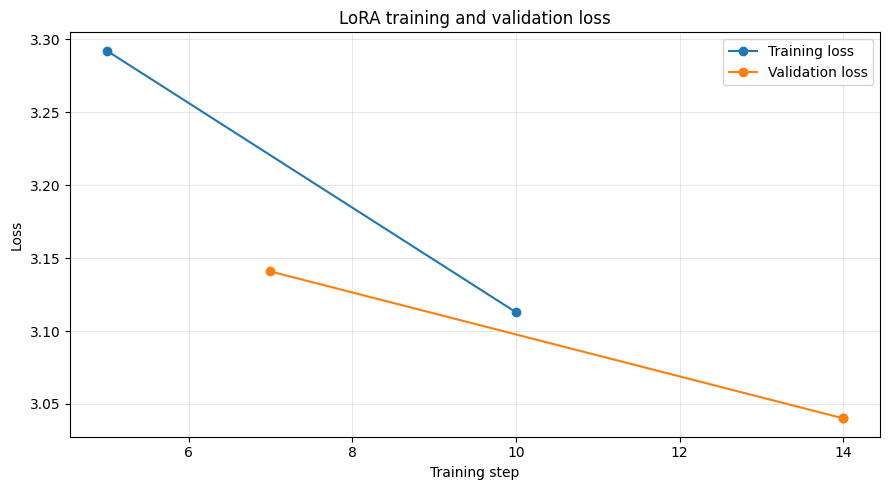

Loss plot saved: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/reports/loss_curve.png


In [11]:
import matplotlib.pyplot as plt

history = json.loads((REPORT_DIR / "loss_history.json").read_text(encoding="utf-8"))
train_points = [(r.get("step"), r.get("loss")) for r in history if r.get("loss") is not None]
eval_points = [(r.get("step"), r.get("eval_loss")) for r in history if r.get("eval_loss") is not None]
if not train_points and not eval_points:
    raise ValueError("No loss values were logged; inspect training logs.")

plt.figure(figsize=(9, 5))
if train_points:
    plt.plot([x for x, _ in train_points], [y for _, y in train_points], marker="o", label="Training loss")
if eval_points:
    plt.plot([x for x, _ in eval_points], [y for _, y in eval_points], marker="o", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("LoRA training and validation loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
LOSS_PLOT = REPORT_DIR / "loss_curve.png"
plt.savefig(LOSS_PLOT, dpi=160, bbox_inches="tight")
plt.show()
print("Loss plot saved:", LOSS_PLOT)

## 11. Generate project report and README

In [12]:
import platform

report = {
    "project": "AI-6 LoRA fine-tuning",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "base_model": MODEL_ID,
    "method": "FP16 base model + PEFT LoRA adapter (not QLoRA)",
    "dataset": {
        "total_examples": len(clean_examples),
        "train_examples": len(train_examples),
        "validation_examples": len(eval_examples),
        "test_examples": len(test_examples),
        "train_file": str(TRAIN_FILE),
        "validation_file": str(VALIDATION_FILE),
        "test_file": str(TEST_FILE),
        "source": "authored starter examples for a learning project",
    },
    "configuration": {
        "lora_rank": 8, "lora_alpha": 16, "lora_dropout": 0.05,
        "learning_rate": LEARNING_RATE, "epochs": NUM_EPOCHS,
        "max_sequence_length": MAX_SEQ_LENGTH,
        "batch_size": BATCH_SIZE, "gradient_accumulation": GRAD_ACCUM,
        "python": platform.python_version(), "torch": torch.__version__,
        "transformers": __import__("transformers").__version__,
        "gpu": torch.cuda.get_device_name(0),
    },
    "metrics": metrics,
    "comparison": {
        "test_prompts": len(comparison),
        "different_output_text_count": different_count,
        "file": str(COMPARISON_FILE),
        "interpretation": "Output differences do not establish quality improvement; manual review is required.",
    },
    "artifacts": {"adapter": str(ADAPTER_DIR), "loss_plot": str(LOSS_PLOT), "loss_history": str(REPORT_DIR / "loss_history.json")},
    "limitations": [
        "Small authored dataset; not a general capability benchmark.",
        "Starter answers need human technical review.",
        "Loss reduction does not prove improved factual accuracy.",
        "Check model license and terms before redistributing artifacts.",
    ],
}
REPORT_FILE = REPORT_DIR / "project_report.json"
REPORT_FILE.write_text(json.dumps(report, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

comparison_md = []
for i, item in enumerate(comparison, 1):
    comparison_md.append(f"### Test prompt {i}\n\n**Prompt:** {item['prompt']}\n\n**Base model:**\n\n{item['base_model_output']}\n\n**Fine-tuned model:**\n\n{item['fine_tuned_output']}\n")

readme = f"""# AI-6: LoRA Fine-Tuning of an Open-Source LLM

## Overview
This learning project fine-tunes `{MODEL_ID}` with FP16 model weights and a PEFT LoRA adapter in Google Colab.

## Dataset
- Total authored examples: {len(clean_examples)}
- Training: {len(train_examples)}
- Validation: {len(eval_examples)}
- Test: {len(test_examples)}
- Data files: `data/train.jsonl`, `data/validation.jsonl`, `data/test.jsonl`
- Loss is computed on assistant response tokens only.

The examples are a small authored starter dataset and should be manually checked for technical correctness. They are not a broad benchmark.

## Training configuration
- Base model: `{MODEL_ID}`
- Method: LoRA (FP16 base + LoRA adapter)
- LoRA rank: 8; alpha: 16; dropout: 0.05
- Learning rate: {LEARNING_RATE}
- Epochs: {NUM_EPOCHS}
- Maximum sequence length: {MAX_SEQ_LENGTH}
- GPU: {torch.cuda.get_device_name(0)}

## Metrics
```json
{json.dumps(metrics, indent=2, default=str)}
```
Loss plot: `reports/loss_curve.png`
Full report: `reports/project_report.json`

## Before/after test comparison
The same {len(comparison)} held-out test prompts were evaluated using separate base and adapter-enabled model instances with deterministic decoding.

Different output text on {different_count}/{len(comparison)} prompts does not prove improvement. Review each answer for correctness, relevance, and consistency.

{chr(10).join(comparison_md)}

## Limitations
- Small dataset and small test set; results may not generalize.
- Loss reduction alone does not establish improved usefulness or factuality.
- Verify the base model's current license and terms before redistributing adapter weights.
- Report unchanged or worse results honestly.

## Reproduction
Run the notebook top to bottom on a compatible Colab GPU. Adapter weights are saved separately and require the compatible base model at inference time.
"""
README_FILE = PROJECT_DIR / "README.md"
README_FILE.write_text(readme, encoding="utf-8")
print("Report:", REPORT_FILE)
print("README:", README_FILE)
print("Loss plot exists:", LOSS_PLOT.exists())
print("Comparison count:", len(comparison))

Report: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/reports/project_report.json
README: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/README.md
Loss plot exists: True
Comparison count: 8


## 12. Package submission artifacts

Create a ZIP containing the adapter, dataset splits, metrics, comparison outputs, loss plot, report, and README. This can take a little time because adapter weights are included.

In [13]:
# Create a portable submission bundle without duplicating checkpoint folders.
BUNDLE_DIR = PROJECT_DIR / "submission_bundle"
if BUNDLE_DIR.exists():
    shutil.rmtree(BUNDLE_DIR)
BUNDLE_DIR.mkdir(parents=True)

shutil.copy2(README_FILE, BUNDLE_DIR / "README.md")
for path in (TRAIN_FILE, VALIDATION_FILE, TEST_FILE):
    shutil.copy2(path, BUNDLE_DIR / path.name)
shutil.copytree(ADAPTER_DIR, BUNDLE_DIR / "adapter", dirs_exist_ok=True)
shutil.copytree(REPORT_DIR, BUNDLE_DIR / "reports", dirs_exist_ok=True)
ZIP_PATH = shutil.make_archive(str(PROJECT_DIR / "AI6_LoRA_Submission"), "zip", root_dir=BUNDLE_DIR)
print("Submission ZIP:", ZIP_PATH)
print("ZIP size (MB):", round(Path(ZIP_PATH).stat().st_size / (1024 * 1024), 2))
print("Project directory:", PROJECT_DIR)
print("Upload the README, loss plot, comparison outputs, and report to your GitHub repository.")

Submission ZIP: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run/AI6_LoRA_Submission.zip
ZIP size (MB): 19.39
Project directory: /content/drive/MyDrive/VEDANT/Study/Valentius Kryptix/AI-6 - Fine-Tuning/lora_run
Upload the README, loss plot, comparison outputs, and report to your GitHub repository.


## Final checklist

- [ ] Notebook ran top-to-bottom without errors.
- [ ] Training loss and validation loss were saved.
- [ ] Adapter and tokenizer were saved to Drive.
- [ ] Base and fine-tuned models were loaded independently.
- [ ] Same held-out test prompts were used for both models.
- [ ] Comparison answers were reviewed for correctness, not just difference.
- [ ] README and report describe the real dataset size, configuration, metrics, and limitations.
- [ ] Current base-model license and redistribution terms were checked.
- [ ] Submission ZIP was created and stored in Google Drive.

**Honest result reporting matters:** this notebook demonstrates the fine-tuning workflow. It cannot guarantee the adapter improves every prompt; describe what the saved evaluation actually shows.